# 國立陽明交通大學 - 多模態影像資料處理 (MMIP) 2026 Fall
## Assignment 08：檢索增強生成（RAG）— 多輪對話 RAG、VideoRAG、RAGAS 評估、GraphRAG

- **學生**：林孟霆（`315833033`）
- **作業規範**：第十堂課程簡報第 72–75 頁
- **完整文字報告與結果分析**：請見同目錄 `README.md`

| 部分 | 內容 | 模型 |
| :--- | :--- | :--- |
| 作業一 | 台灣勞動法規（14 部法規、842 條）多輪對話 RAG：QA Dataset、Chunk Size / Overlap / Top-K、Prompting Technique、UI | bge-m3、bge-reranker-v2-m3、Qwen3-4B-Instruct-2507 |
| 作業二 | 自行錄製影片的多輪對話 VideoRAG（改編 VideoRAG：K-means 代表畫面 + 子集挑選） | Whisper large-v3-turbo、Chinese-CLIP、Qwen3-VL-2B |
| 作業三 | 以 RAGAS 指標評估作業一；延伸到 VideoRAG（影片檢索、時間定位、多模態忠實度） | Gemini 評審（沒有 Key 時用 Qwen3-4B） |
| 作業四 | 把 Self-RAG 論文 Graph 化，25 題 Benchmark 比較 GraphRAG 與一般 RAG | Qwen3-4B、bge-m3、networkx |

### 在 Google Colab 執行（T4 GPU，約 2.5–3 小時；每個步驟都有快取，斷線重跑會從中斷處接續）
1. 作業二的影片已經剪好放在 `Data/videos/`（5 支短片：2 支論文報告有說話、3 支專題 demo 操作沒有說話，來源見 README 2-1），評估用的 18 題問答與 2 段多輪對話在 `Data/video_qa.json`。
2. 把 `HW08/` 放到 Google Drive 的 `MyDrive/MMIP/HW08`（原始未剪輯的錄影 `videos/` 不需要上傳）。
3. 「執行階段 → 變更執行階段類型」選 **T4 GPU**；左側「Secrets」加入 `GEMINI_API_KEY`（作業三、四的評審；沒有 Key 改用本地模型評審）。
4. 依序執行。最後兩格是聊天介面（會一直執行，看完手動停止），倒數第三格下載 `HW08_results.zip`。

In [1]:
%matplotlib inline
import os, sys
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/MMIP/HW08')
    !pip -q install -r requirements.txt
sys.path.insert(0, os.getcwd())

import torch, pandas as pd, numpy as np
from IPython.display import display, Markdown
from Code.common import gpu_info, out_path, save_json, load_json, free_gpu
from Code.gemini import GeminiJudge, get_api_key
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 220)
print('Working dir:', os.getcwd()); print(gpu_info())
print('GEMINI_API_KEY:', 'found' if get_api_key() else 'not found -> judge = local Qwen3-4B')
gemini = GeminiJudge(out_path('gemini_cache.json'))

Mounted at /content/drive
Working dir: /content/drive/MyDrive/MMIP/HW08
{'device': 'cuda', 'name': 'Tesla T4', 'vram_gb': 14.56, 'capability': '7.5', 'torch': '2.14.1+cu130'}
GEMINI_API_KEY: found


---
## 作業一：多輪對話 RAG
### 資料：台灣勞動法規
14 部勞動相關法規（勞動基準法、勞工請假規則、性別平等工作法、勞工退休金條例、就業保險法…），共 842 條，從全國法規資料庫下載（`Code/prepare_data.py`；法規不受著作權保護）。評估資料是手寫的 47 題單輪問答（每題另有一個口語問法）與 11 段 3 輪的多輪對話（`Code/qa_data.py`），每題都標了正確條文。

In [2]:
from Code import corpus, hw1, rag as R, ragas_eval
from Code.qa_data import SINGLE, DIALOGUES
arts, meta = corpus.load_articles()
display(pd.DataFrame(meta['laws']).T)
print(f"{len(arts)} articles, {sum(len(a['text']) for a in arts):,} characters; evaluation: {len(SINGLE)} questions x 2 wordings + {sum(len(d['turns']) for d in DIALOGUES)} dialogue turns")
print(SINGLE[11]); print(DIALOGUES[1]['turns'][1])

,pcode,articles,date
勞動基準法,N0030001,98,民國 113 年 07 月 31 日
勞動基準法施行細則,N0030002,63,民國 113 年 03 月 27 日
勞工請假規則,N0030006,13,民國 115 年 09 月 30 日
性別平等工作法,N0030014,49,民國 112 年 08 月 16 日
性別平等工作法施行細則,N0030015,19,民國 115 年 04 月 08 日
勞工退休金條例,N0030020,67,民國 108 年 05 月 15 日
最低工資法,N0030028,19,民國 112 年 12 月 27 日
職業安全衛生法,N0060001,61,民國 114 年 12 月 19 日
就業服務法,N0090001,84,民國 114 年 01 月 20 日
勞資爭議處理法,N0020007,67,民國 110 年 04 月 28 日


842 articles, 123,158 characters; evaluation: 47 questions x 2 wordings + 33 dialogue turns
{'id': 'Q12', 'question': '適用勞退新制的勞工被資遣時，資遣費如何計算？', 'paraphrase': '我是勞退新制，被資遣可以拿多少資遣費？', 'answer': '按工作年資每滿一年發給二分之一個月平均工資，未滿一年以比例計給，最高以 6 個月平均工資為限，於終止勞動契約後 30 日內發給。', 'gold': ['勞工退休金條例第12條']}
{'question': '那休息日呢？', 'answer': '休息日工作 2 小時以內另再加給 1 又 1/3 以上，2 小時後另再加給 1 又 2/3 以上。', 'gold': ['勞動基準法第24條']}


In [3]:
from Code.embed import Embedder, Reranker
from Code.llm import LLM
emb = Embedder(cache_dir=out_path('emb_cache'))
reranker = Reranker()
llm = LLM(out_path('llm_cache.json'))          # Qwen3-4B is loaded on the first uncached generation

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/444 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (10 outputs left out)

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

### 作業一進階：找出表現最穩定的 Chunk Size、Overlap Size、Top-K
13 種切塊（固定長度 128 / 256 / 512 / 1024 字 × 重疊 0 / 12.5% / 25%，以及「一條一塊」）× Top-K 1 / 3 / 5 / 10，用 47 題的**正式問法與口語問法**檢索（只用 embedding，不經過 LLM）。
- **Recall@k**：前 k 個 chunk 涵蓋的正確條文比例；**MRR**：第一個正確 chunk 名次的倒數（投影片第 10 頁的計分方式）。
- **穩定度**：(1) 1,000 次 bootstrap 重抽題目後 Recall 的 2.5 百分位數（運氣差時的表現）；(2) 正式與口語問法的差距。
- 選擇規則：檢索內容不超過 3,000 字（4B 模型的輸入預算）的設定中，取 bootstrap 下界最高者，平手再看問法差距與內容長度。

,config,size,overlap,chunks,mean_chunk_chars,k,context_chars,hit_formal,hit_colloquial,recall,recall_low95,style_gap,mrr
10,fixed128_ov32,128,32,1400,145,5,723,1.000,0.872,0.936,0.883,0.128,0.787
18,fixed256_ov32,256,32,603,271,5,1353,0.979,0.894,0.931,0.883,0.096,0.840
50,article,article,-,842,167,5,836,1.000,0.872,0.936,0.883,0.128,0.810
30,fixed512_ov64,512,64,304,519,5,2595,1.000,0.872,0.931,0.878,0.138,0.784
6,fixed128_ov16,128,16,1201,145,5,723,0.957,0.894,0.926,0.872,0.064,0.754
14,fixed256_ov0,256,0,531,269,5,1347,0.979,0.872,0.920,0.862,0.117,0.769
34,fixed512_ov128,512,128,352,521,5,2604,0.915,0.894,0.904,0.840,0.021,0.739
26,fixed512_ov0,512,0,268,517,5,2586,0.957,0.851,0.904,0.840,0.106,0.730


chosen: article top-k = 10 | recall 0.979 | bootstrap low 0.947


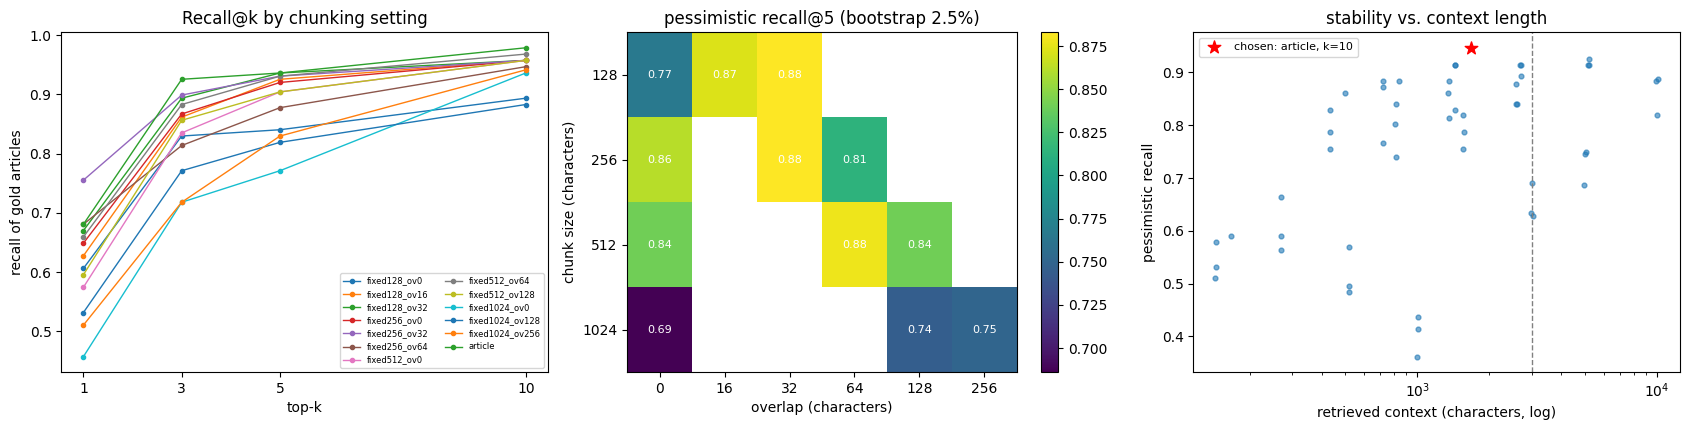

In [4]:
G, per_query = hw1.grid_search(emb, arts)
best = hw1.pick_best(G)
display(G[G['k'] == 5].sort_values('recall_low95', ascending=False).round(3).head(8))
print('chosen:', best['config'], 'top-k =', int(best['k']), '| recall', round(best['recall'], 3), '| bootstrap low', round(best['recall_low95'], 3))
hw1.plot_grid(G, best)
BEST_CFG = next(c for c in hw1.GRID if corpus.cfg_name(c) == best['config'])
TOP_K = int(best['k'])

### 作業一基礎：自製 QA Dataset 與 Embedding
依投影片第 12 頁「將文本轉換成 QA 形式，並把 Q 轉換成 Embedding」：用 Qwen3-4B 替選定切塊的每個 chunk 產生 3 個 5W1H 角度的問題（含口語問法），與 chunk 本身一起建索引——chunk 的分數取「chunk 本身」與「它的問題」相似度的最大值。QA Dataset = 自動產生的問答 + 47 題手寫問答 + 11 段多輪對話（`Output/hw1_qa_dataset.json`）。

In [5]:
index, qa = hw1.build_index(emb, llm, arts, BEST_CFG)
counts = hw1.save_dataset(index, qa)
display(pd.Series(counts, name='count'))
print('Embedding 數量 =', index.n_embeddings, '(chunks + synthetic questions)')
for x in qa[:6]: print(f"  Q: {x['question']}  ->  {', '.join(x['articles'])}")

,count
n_chunks,842
n_synthetic_questions,1794
n_handwritten_questions,47
n_dialogue_turns,33
n_embeddings,2636


Embedding 數量 = 2636 (chunks + synthetic questions)
  Q: 這條法規是誰要遵守的？  ->  勞動基準法第1條
  Q: 我們公司跟員工簽的合約，應該要符合什麼最低標準才不會違法？  ->  勞動基準法第1條
  Q: 如果雇主想給員工薪水比法律規定還低，這樣做會有什麼後果嗎？  ->  勞動基準法第1條
  Q: 誰可以被稱為勞工？  ->  勞動基準法第2條
  Q: 如果我工作了五個月，怎麼算我的平均工資？  ->  勞動基準法第2條
  Q: 要派單位和派遣事業單位之間是怎麼訂立要派契約的？  ->  勞動基準法第2條


### 檢索強化：合成問題、Re-ranker（兩階段檢索，投影片第 23–30 頁）、Query 轉換（第 16 頁）

In [6]:
A = hw1.ablation(index, emb, reranker)
display(A.round(3))
# the system uses the retrieval setting with the best recall@TOP_K on the ablation (ties -> MRR)
best_r = A.sort_values([f'recall@{TOP_K}', 'mrr'], ascending=False).iloc[0]['retrieval']
USE_Q, USE_RR = best_r in ('+ synthetic questions', '+ both'), best_r in ('+ re-ranker', '+ both')
print(f'retrieval used by the system: {best_r} (synthetic questions={USE_Q}, re-ranker={USE_RR})')
rag = R.RAG(llm, emb, index, reranker if USE_RR else None, top_k=TOP_K, prompt='grounded', query_mode='rewrite',
            use_questions=USE_Q)
T = hw1.query_transform_eval(rag)
display(T.round(3))

,retrieval,hit@1,hit@3,hit@5,hit@10,recall@1,recall@3,recall@5,recall@10,mrr
0,chunks only,0.691,0.926,0.936,0.979,0.681,0.926,0.936,0.979,0.810
1,+ synthetic questions,0.532,0.766,0.819,0.872,0.521,0.761,0.814,0.872,0.655
2,+ re-ranker,0.755,0.947,0.957,1.000,0.745,0.947,0.957,1.000,0.846
3,+ both,0.798,0.915,0.926,0.936,0.787,0.915,0.926,0.936,0.856


retrieval used by the system: + re-ranker (synthetic questions=False, re-ranker=True)


,query_mode,hit@10 all turns,turn 1,turns 2-3 (need context)
0,none,0.667,0.909,0.545
1,rewrite,0.939,0.909,0.955
2,multi,0.970,1.000,0.955
3,stepback,0.939,0.909,0.955


### 作業一基礎：多輪對話經過 RAG 系統後的回覆與 Reference
11 段對話依序送進系統，第 t 輪的歷史是系統自己前幾輪的回答；第 2、3 輪多是「那休息日呢？」「這幾天有薪水嗎？」這類需要上下文的問題，系統先改寫成可獨立檢索的問題，再檢索、回答並標出引用條文（★）。

In [7]:
dialog_res = hw1.run_dialogues(rag)
for did in ('M02', 'M03', 'M09'):
    print('=' * 100); hw1.show_dialogue(dialog_res, did)
turns = [r for v in dialog_res.values() for r in v]
print(f"\n33 turns: retrieved a gold article {np.mean([r['retrieved_gold'] for r in turns]):.0%}, cited a gold article {np.mean([r['cited_gold'] for r in turns]):.0%}")

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

  [OOM] retrying with batch size 4
【第 1 輪】使用者：老闆叫我平日下班後加班 3 小時，加班費怎麼算？
   助理：平日加班3小時，應依《勞動基準法》第24條計算：前2小時按平日每小時工資額加給三分之一，後1小時按平日每小時工資額加給三分之二 [1]。
   ★[1] 勞動基準法第24條  score=0.0967
    [2] 勞動基準法施行細則第13條  score=0.0461
    [3] 勞動基準法施行細則第22-3條  score=0.0243
    [4] 勞動基準法施行細則第22-1條  score=0.0192
    [5] 勞動基準法第39條  score=0.0188
    [6] 勞動基準法第32-1條  score=0.0182
    [7] 勞動基準法第70條  score=0.0114
    [8] 勞動基準法第30條  score=0.0112
    [9] 勞動基準法施行細則第37條  score=0.007
    [10] 勞動基準法施行細則第24-1條  score=0.0069
   標準答案：前 2 小時按平日每小時工資額加給三分之一以上，第 3 小時加給三分之二以上。  （檢索到正確條文：True）
【第 2 輪】使用者：那休息日呢？
   改寫後的檢索問題：如果公司在休息日要求員工加班3小時，這段加班時間應如何計算加班費？
   助理：平日加班3小時，前2小時按平日每小時工資額加給三分之一，後1小時加給三分之二 [2]。若為休息日加班，則工作時間在2小時內，應另加給一又三分之一以上工資；超過2小時後，應另加給一又三分之二以上工資 [2]。
    [1] 勞動基準法第32-1條  score=0.1774
   ★[2] 勞動基準法第24條  score=0.0693
    [3] 勞動基準法施行細則第22-1條  score=0.0383
    [4] 勞動基準法施行細則第13條  score=0.0349
    [5] 勞動基準法第36條  score=0.0345
    [6] 勞動基準法第39條  score=0.0231
    [7] 勞動基準法施行細則第22-3條  score=0.0223
    [8] 勞動基準法第70條  score=0

### 作業一進階：找出最合適的 Prompting Technique
同樣的檢索結果，比較 4 種 Prompt：`basic`（直接給資料）、`grounded`（角色 + 只能依據資料 + [n] 引用 + 資料不足就說不知道）、`cot`（grounded + 先分析再回答）、`fewshot`（grounded + 一個示範問答），以 RAGAS 指標（定義見作業三）比較，另列不經檢索的 Qwen3-4B 作為對照。

In [8]:
answers = hw1.answer_single(rag)
judge = ragas_eval.Judge(gemini, llm)
print('judge:', judge.name)
ragas_dfs = {}
for name in ('basic', 'grounded', 'cot', 'fewshot', 'no_rag'):
    ragas_dfs[name], _ = ragas_eval.evaluate(name, answers[name], judge, llm, emb)
S = ragas_eval.summarize(list(ragas_dfs.values()))
display(S.round(3))
cites = {p: np.mean([any(x['cited'] and set(x['articles']) & set(r['gold']) for x in r['references']) for r in answers[p]]) for p in ('basic', 'grounded', 'cot', 'fewshot')}
print('answers that cite a gold article:', {k: f'{v:.0%}' for k, v in cites.items()})

  [answer] 16/47 generated  233s
  [answer] 32/47 generated  443s
  [answer] 47/47 generated  624s
  [answer] 16/47 generated  70s
  [answer] 32/47 generated  135s
  [answer] 47/47 generated  193s
  [answer] 16/47 generated  169s
  [answer] 32/47 generated  331s
  [answer] 47/47 generated  457s
  [answer] 16/47 generated  67s
  [answer] 32/47 generated  127s
  [answer] 47/47 generated  186s
judge: gemini (gemini-3.5-flash-lite)
  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 5s
  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 5s
  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 10s
  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model

,system,faithfulness,answer_relevancy,context_precision,context_recall,answer_correctness,judge_ok
0,basic,0.964,0.827,0.907,1.0,0.770,1.000
1,grounded,0.970,0.869,0.922,1.0,0.772,1.000
2,cot,0.989,0.872,0.913,1.0,0.744,1.000
3,fewshot,0.967,0.853,0.912,1.0,0.742,1.000
4,no_rag,NaN,0.849,NaN,NaN,0.208,0.957


answers that cite a gold article: {'basic': '2%', 'grounded': '96%', 'cot': '100%', 'fewshot': '94%'}


---
## 作業二：多輪對話 VideoRAG
改編自 VideoRAG（投影片第 56–63 頁）：
1. **建立索引**：Whisper 逐字稿（含時間）＋ 每秒一張畫面 → Chinese-CLIP → K-means 選出 64 張代表畫面 → Qwen3-VL-2B 為每張代表畫面寫一句描述（讓沒有說話的操作影片也能用文字檢索）。
2. **影片檢索**：文字片段（bge-m3）與畫面（CLIP）兩種排名做 reciprocal rank fusion。
3. **Frame Selection**：在選中的影片中隨機抽 40 組 6 張的子集，以「子集平均 CLIP 向量 · 問題向量」加上時間先驗評分（論文用訓練好的 MLP，這裡沒有訓練資料，改用 zero-shot 分數）。
4. **生成**：Qwen3-VL-2B 看選出的畫面與文字片段回答，並標出【影片 mm:ss】。多輪對話先把問題改寫成獨立問題。

先釋放 Qwen3-4B 的 GPU 記憶體（作業三、四會自動重新載入）。

In [9]:
from Code import video as V
llm.unload(); free_gpu()
videos = V.list_videos()
print(len(videos), 'videos:', [os.path.basename(v) for v in videos])
HAS_VIDEO = len(videos) > 0
if not HAS_VIDEO:
    print('Data/videos/ is empty -> record the videos first (Data/videos/README.md); 作業二 and 作業三 advanced are skipped')

5 videos: ['op_database_tables.mp4', 'op_patient_inference.mp4', 'op_review_report.mp4', 'talk_outline.mp4', 'talk_paper_intro.mp4']


In [10]:
# 作業二：建立影片索引（每支影片的結果快取在 Output/video_index/）
if HAS_VIDEO:
    recs, clip = V.build_index(videos)
    for r in recs:
        print('=' * 100)
        print(f"{r['name']}: {r['duration']:.0f} s, speech={r['has_speech']}, {len(r['reps'])} representative frames")
        for u in r['units'][:12]:
            print(f"  [{V.fmt(u['start'])}] ({u['kind']}) {u['text']}")

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.01k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/110k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  753MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

[video] indexing op_database_tables.mp4


model.safetensors: reconstructing file:   0%|          |  0.00B /  753MB            

model.safetensors: downloading bytes:           |  0.00B            

[video] indexing op_patient_inference.mp4
[video] indexing op_review_report.mp4
[video] indexing talk_outline.mp4
[video] indexing talk_paper_intro.mp4
op_database_tables: 37 s, speech=False, 37 representative frames
  [00:00] (visual) 醫學影像報告審核系統，顯示肺部X光片與審核欄位。
  [00:01] (visual) 在醫學影像分析平台進行X光影像分析，顯示結果與報告。
  [00:02] (visual) 在雲端診斷平台進行胸部X光影像分析。
  [00:03] (visual) 在一個資料庫管理工具中，正在查看並操作「Tables」的資料。
  [00:04] (visual) 在 Neovim 編輯器中，正在查看並操作一個名為 'tables' 的資料表。
  [00:05] (visual) 瀏覽器中顯示一個正在載入的網頁，頁面為黑色背景。
  [00:06] (visual) 在 Neovim 編輯器中，正在查看一個名為 'CheXRayAI' 的項目，並在 'Tables' 模塊中進行操作。
  [00:07] (visual) 在 Neovim 編輯器中，正在查看並操作資料庫表結構。
  [00:08] (visual) 在 Neovim 中使用 SQL 軟體，查看資料庫表結構。
  [00:09] (visual) 在一個資料庫管理介面中，正在操作「production」分支的「Tables」，並顯示了「a_inference_results」等表格名稱。
  [00:10] (visual) 在資料庫管理工具中，正在查看並操作「patient_data」表。
  [00:11] (visual) 在資料庫管理介面中，正在查看並操作「a_inference_results」表。
op_patient_inference: 20 s, speech=False, 20 representative frames
  [00:00] (visual) 在瀏覽器中使用醫療助理模型進行影像分析。
  [00:01] (vi

In [11]:
if HAS_VIDEO:
    vlm = V.VLM()
    vrag = V.VideoRAG(recs, clip, emb, vlm)
    qa_v = load_json('Data/video_qa.json')
    demo_turns = qa_v['dialogues'][0]['turns'] if qa_v.get('dialogues') else [{'question': '這些影片在做什麼？'}, {'question': '第一個步驟是什麼？'}]
    hist = []
    for t in demo_turns:
        res = vrag.answer(t['question'], hist)
        hist.append((t['question'], res['answer']))
        print(f"使用者：{t['question']}\n  改寫：{res['standalone']}\n  候選影片：{res['video_scores']}\n  助理：{res['answer']}")
        print('  使用的畫面：', [f"{f['video']} {V.fmt(f['t'])}" for f in res['frames']])

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

使用者：醫療助理系統裡，上傳胸腔 X 光之後會經過哪些模型？
  改寫：醫療助理系統裡，上傳胸腔 X 光之後會經過哪些模型？
  候選影片：{'op_review_report': 0.84547, 'op_patient_inference': 0.82938, 'op_database_tables': 0.70346}
  助理：系統上傳胸腔 X 光後，會經過影像分割模型與肺部病變識別模型，以進行肺部病變的評估與分析。【op_review_report 00:01】
  使用的畫面： ['op_review_report 00:01', 'op_review_report 00:03', 'op_review_report 00:04', 'op_review_report 00:05', 'op_review_report 00:06', 'op_review_report 00:12']
使用者：那產生的報告醫師可以修改嗎？
  改寫：產生的報告是否可以由醫師修改？
  候選影片：{'op_database_tables': 0.9605, 'op_review_report': 0.79709, 'op_patient_inference': 0.72175}
  助理：【op_database_tables 00:33–00:34】產生的報告可以由醫師修改，因為資料庫管理工具中顯示「medical_reports」表的資料可被編輯。
  使用的畫面： ['op_database_tables 00:00', 'op_database_tables 00:01', 'op_database_tables 00:02', 'op_database_tables 00:24', 'op_database_tables 00:26', 'op_database_tables 00:27']
使用者：送出之後會存到哪裡？
  改寫：上傳胸腔 X 光後，資料會存放在哪裡？
  候選影片：{'op_review_report': 0.99975, 'op_database_tables': 0.96269, 'op_patient_inference': 0.76856}
  助理：上傳的胸腔 X 光影像會存入資料庫，並由系統自動產生評估報告，供醫師審核與修改。【o

---
## 作業三：評估 RAG 系統
### 基礎：以 RAGAS 評估作業一
指標依 RAGAS 的定義：**faithfulness**（回答拆成陳述，有幾成能由檢索內容推得）、**answer relevancy**（由回答反推問題，與原問題的相似度）、**context precision**（有用的 chunk 是否排在前面）、**context recall**（標準答案的陳述有幾成在檢索內容中）、**answer correctness**（回答與標準答案的陳述層級 F1）。為了不超過 Gemini 免費額度，每筆回答只呼叫一次評審，同時取得所有判斷；分數由程式依判斷計算。上面作業一已評估 47 題 × 5 個系統，這裡再評估 33 輪多輪對話，並檢查評審的可靠度（同一批回答由 Gemini 與本地 Qwen3-4B 各評一次）。

In [12]:
# GPU: free the video models before Qwen3-4B (judge, answer relevancy) is loaded again
if HAS_VIDEO and 'vlm' in globals():
    vrag.vlm = None; del vlm; free_gpu()
dialog_recs = [dict(r, id=f"{did}-{r['turn']}") for did, v in dialog_res.items() for r in v]
ragas_dfs['multi-turn (grounded)'], _ = ragas_eval.evaluate('dialogues', dialog_recs, judge, llm, emb)
S = ragas_eval.summarize(list(ragas_dfs.values()))
display(S.round(3))
if judge.gemini is not None:
    D = ragas_eval.judge_agreement(answers['grounded'], judge, ragas_eval.Judge(None, llm), llm, emb, 'grounded')
    display(D.round(3))

  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 5s
  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 5s
  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 5s


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  [answer relevancy] 16/29 generated  24s
  [answer relevancy] 29/29 generated  45s


,system,faithfulness,answer_relevancy,context_precision,context_recall,answer_correctness,judge_ok
0,basic,0.964,0.827,0.907,1.000,0.770,1.000
1,grounded,0.970,0.869,0.922,1.000,0.772,1.000
2,cot,0.989,0.872,0.913,1.000,0.744,1.000
3,fewshot,0.967,0.853,0.912,1.000,0.742,1.000
4,no_rag,NaN,0.849,NaN,NaN,0.208,0.957
5,dialogues,0.892,0.725,0.782,0.939,0.686,1.000


  [judge] 16/47 generated  254s
  [judge] 32/47 generated  456s
  [judge] 47/47 generated  578s


,metric,gemini_mean,local_mean,mean_abs_diff,pearson_r
0,faithfulness,0.970,0.898,0.093,0.291
1,context_precision,0.922,0.948,0.066,0.646
2,context_recall,1.000,0.989,0.011,NaN
3,answer_correctness,0.772,0.895,0.177,0.508


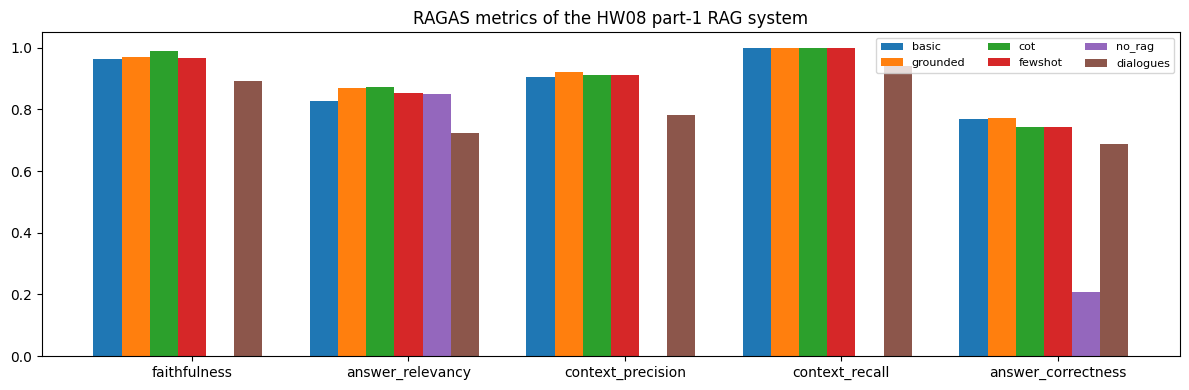

In [13]:
import matplotlib.pyplot as plt
M = ragas_eval.METRICS
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(M))
for i, (_, r) in enumerate(S.iterrows()):
    ax.bar(x + (i - len(S) / 2) * 0.13, [r[m] for m in M], 0.13, label=r['system'])
ax.set_xticks(x); ax.set_xticklabels(M); ax.set_ylim(0, 1.05); ax.legend(fontsize=8, ncol=3); ax.set_title('RAGAS metrics of the HW08 part-1 RAG system')
plt.tight_layout(); plt.savefig(out_path('hw3_ragas.png'), dpi=130); plt.show()

### 進階：延伸到 VideoRAG 的評估
在 RAGAS 之外加上影片特有的面向：**影片檢索**（video hit@1/3）、**時間定位**（使用的片段 / 畫面是否落在標準答案的時間區間、引用的時間點是否正確、送進模型的畫面有幾成在區間內）、**多模態 RAGAS**（Gemini 直接看選出的畫面判斷回答是否有根據、畫面是否有用）。並做兩組消融：模態（畫面 + 文字 / 只有文字 / 只有畫面）與畫面挑選（VideoRAG 挑選 vs 均勻取樣），依問題類型（語音 / 畫面）分開統計。

In [14]:
from Code import video_eval
if HAS_VIDEO:
    llm.unload(); free_gpu()                       # GPU: Qwen3-4B out, Qwen3-VL back in
    if getattr(vrag, 'vlm', None) is None:
        vlm = V.VLM(); vrag.vlm = vlm
    VS, VT = video_eval.evaluate(vrag, gemini if gemini.available or gemini.cache else None)
    if VS is not None:
        display(VS.round(3)); display(VT.round(3))

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 5s
  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 5s


,variant,video_hit@1,video_hit@3,temporal_recall,frame_precision,citation_accuracy,faithfulness,context_recall,frame_usefulness,answer_correctness
0,VideoRAG (frames + text),0.833,0.944,0.833,0.657,0.778,0.898,0.870,0.593,0.730
1,text only,0.833,0.944,0.833,NaN,0.778,1.000,0.431,NaN,0.407
2,frames only,0.833,0.944,0.778,0.657,0.667,0.927,0.824,0.549,0.595
3,"frames + text, uniform frames",0.833,0.944,0.833,0.639,0.833,0.898,0.833,0.352,0.696
4,multi-turn dialogue,0.333,1.000,0.333,0.306,0.333,0.917,0.667,0.194,0.444


,variant,type,temporal_recall,answer_correctness
0,VideoRAG (frames + text),speech,0.875,0.833
1,VideoRAG (frames + text),visual,0.800,0.647
2,text only,speech,0.875,0.792
3,text only,visual,0.800,0.100
4,frames only,speech,0.750,0.629
5,frames only,visual,0.800,0.572
6,"frames + text, uniform frames",speech,0.875,0.875
7,"frames + text, uniform frames",visual,0.800,0.553


---
## 作業四：GraphRAG
論文：**Self-RAG**（Asai et al., 2023，arXiv 2310.11511，CC BY 4.0）。Qwen3-4B 從每個 1,200 字的段落抽出實體與關係 → 名稱正規化合併 → networkx 圖 → Louvain 社群 → 每個社群一份報告。查詢：**local**（相似實體 + 一階鄰居關係 + 來源段落）、**global**（每個社群報告先回答並評分，再整合）、**graph**（由 LLM 判斷題型後選 local 或 global）；對照組 **vector**（一般 RAG：前 5 個段落）。Benchmark：25 題（local 14、multi-hop 7、global 4），每題列出關鍵要點，評審逐點檢查。

,value
text_units,85
unparsed_units,46
entities,267
relations,244
communities,28
connected_components,61
entity_types,"{'CONCEPT': 85, 'TASK': 43, 'RESULT': 24, 'METHOD': 18, 'ORGANIZATION': 18, 'DATASET': 16, 'MODEL': 14, 'METRIC': 14..."


[community 0] Self-RAG: Self-Reflective Retrieval-Augmented Generation (46 entities)
   Self-RAG is a self-reflective RAG method that generates reflection tokens during inference to assess output support, improving fluency and completeness. It trains a generator model M on a curated corpus of 150k instances with interleaved passages and reflection tokens, using a critic model C to eval
[community 1] Self-RAG Retrieval Mechanism (3 entities)
   In SELF-RAG, a retrieval token (TOKEN) triggers the retriever model (MODEL) to fetch K documents on demand. The retriever model retrieves exactly K documents in response to the token. This mechanism enables dynamic, context-aware document retrieval, enhancing reasoning accuracy. The relationship is 
[community 2] Origin of California's Name (4 entities)
   California is named after a fictional island in the 16th-century Spanish novel Las Sergas de Esplandián. This novel, a 16th-century novel, features a fictional island that inspired the name of 

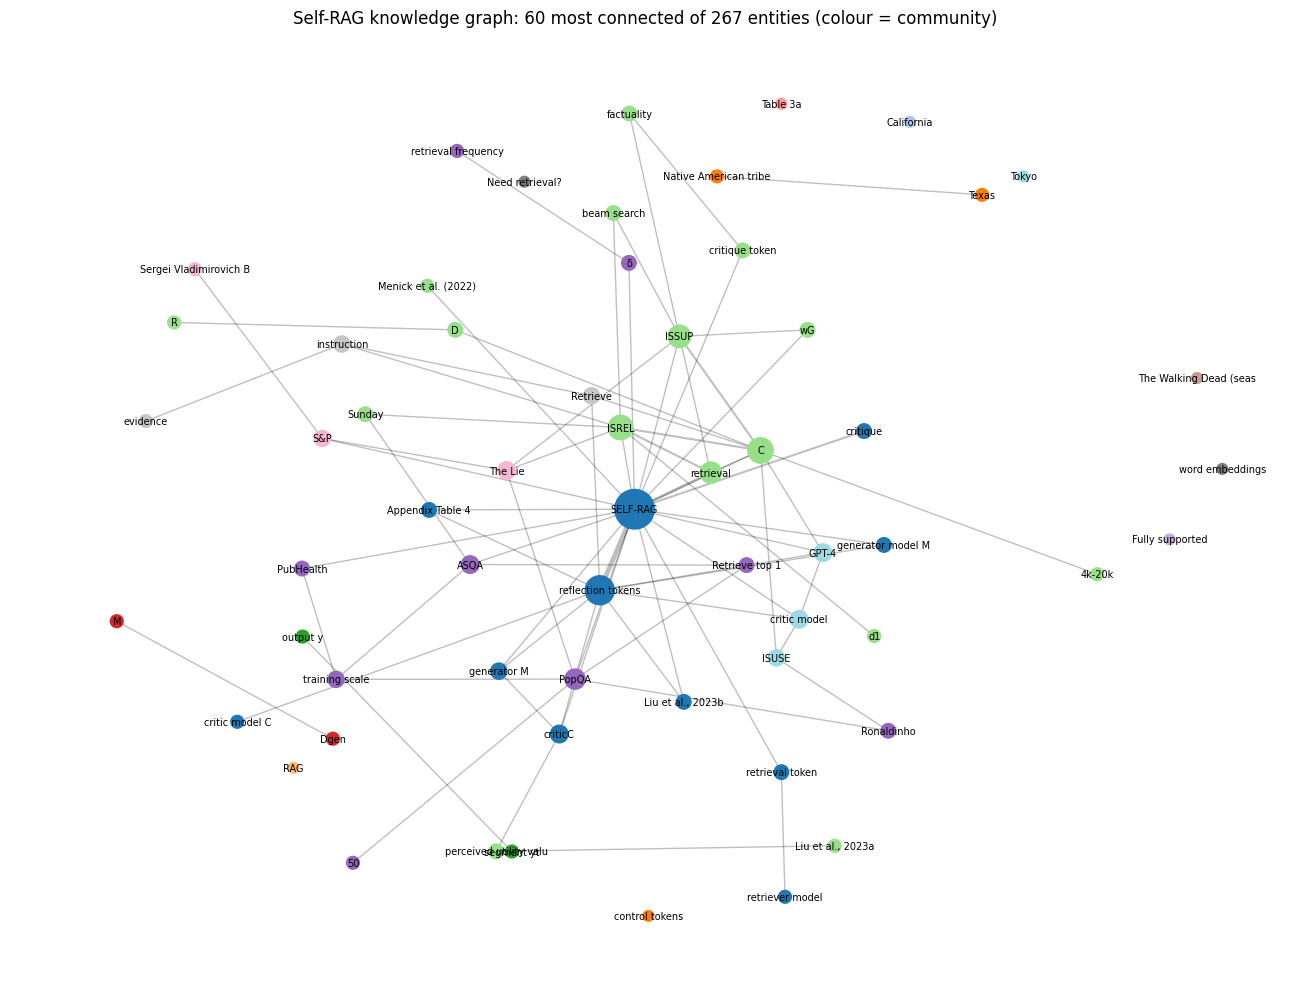

In [15]:
from Code import graphrag as GR
from Code.graph_data import GRAPH_QA
if HAS_VIDEO and 'vlm' in globals():
    vrag.vlm = None; del vlm; free_gpu()           # GPU: free Qwen3-VL before Qwen3-4B builds the graph
gindex = GR.GraphIndex(llm, emb).build()
display(pd.Series(gindex.stats(), name='value'))
for c in gindex.comms[:6]:
    print(f"[community {c['id']}] {c['title']} ({len(c['members'])} entities)\n   {c['summary'][:300]}")
gindex.plot()

In [16]:
qs = [g['question'] for g in GRAPH_QA]
graph_recs = {}
for mode in ('vector', 'local', 'global', 'graph'):
    p = out_path(f'hw4_answers_{mode}.json')
    graph_recs[mode] = load_json(p) if os.path.exists(p) else gindex.answer(qs, mode)
    save_json(graph_recs[mode], p)
judge_fn = (lambda k, p: gemini.judge_obj(k, p)) if (gemini.available or gemini.cache) else \
           (lambda k, p: GR.parse_json(llm.one([{'role': 'user', 'content': p}], 300), None))
GS, GT, Gdf = GR.evaluate(graph_recs, GRAPH_QA, judge_fn)
display(GS.round(3)); display(GT.round(3))
print('routing of the graph mode:', pd.Series([r['route'] for r in graph_recs['graph']]).value_counts().to_dict())
for g, a, b in list(zip(GRAPH_QA, graph_recs['vector'], graph_recs['graph']))[21:23]:
    print('=' * 100); print(g['question']); print('  vector:', a['answer'][:300]); print('  graph :', b['answer'][:300])

,system,key_point_recall,correctness,has_error
0,vector,0.643,3.36,0.24
1,local,0.233,1.88,0.28
2,global,0.279,1.92,0.52
3,graph,0.251,1.80,0.44


type,system,local,multihop,global
0,vector,0.673,0.598,0.617
1,local,0.113,0.388,0.383
2,global,0.143,0.381,0.575
3,graph,0.095,0.352,0.617


routing of the graph mode: {'global': 18, 'local': 7}
請用 5W1H 整理這篇論文：誰提出、要解決什麼問題、提出什麼方法、怎麼做？
  vector: 誰：Akari Asai 等人；要解決問題：LLMs 因僅依賴內建知識導致事實錯誤與不正確建議；提出方法：Self-RAG（Self-Reflective Retrieval-Augmented Generation）；怎麼做：透過自我反思、檢索相關知識、評估輸出正確性與事實性，並使用權重（ISREL, ISSUP, ISUSE）與檢索門檻控制檢索行為。
  graph : Self-RAG 由 Liu et al. 提出，受 Ziegler et al. (2019)、Ouyang et al. (2022) 及控制標記啟發。解決 RAG 中輸出缺乏來源支持、不完整或不正確的問題，提出自我反思機制，透過生成反思標記（如 ISREL、ISSUP）評估文段相關性與支持度，並以權重 wG 調整判斷。做法為：訓練生成模型 M 在擴充語料庫中預測反思令牌與檢索段落，使用評估模型 C 在離線模式下評估並更新資料，推理時生成反思標記檢視支援程度，並依結果調整輸出。
請完整說明 Self-RAG 從訓練到推論的流程。
  vector: Self-RAG 在訓練階段，將反射標記（reflection tokens）統一為下一個 token 預測，並訓練生成器 LM 在包含檢索段落與反射標記的資料集中生成文本。訓練時，由評論模型（critic model）預測反射標記，評估檢索段落與輸出品質。推論時，針對每一段生成，根據反射標記的預測（如是否需檢索、內容是否被支持）進行控制，支援自適應檢索與段落級束搜，並透過反射標記強制軟或硬約束，確保輸出內容與段落相關且有事實支持。
  graph : Self-RAG 的訓練流程於擴充語料庫 Dgen 上進行，包含原始輸入、反思標記（reflection tokens）與檢索段落，使用「mask out」方法維持穩定性，模型 M 以下一個詞預測輸出與反思標記。訓練中，GPT-4 生成反思標記並訓練評論模型 C，預測 ISUSE（五類效用標記）以判斷輸出足夠性，實現檢索-free 監督。推論時，模型生成反思標記，評論模型根據 ISUSE 判斷內

### 打包結果
`Output/`（所有表格、圖、回答、評審快取）壓縮成 `HW08_results.zip`（不含 embedding 快取與影片索引的圖片）。

In [17]:
import zipfile, glob
with zipfile.ZipFile('HW08_results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob('Output/**', recursive=True):
        if os.path.isfile(f) and '/emb_cache/' not in f.replace(os.sep, '/') and not f.endswith(('.npy', '.jpg')):
            z.write(f)
print(f"HW08_results.zip: {os.path.getsize('HW08_results.zip') / 2**20:.1f} MiB")
if IN_COLAB:
    from google.colab import files
    files.download('HW08_results.zip')

HW08_results.zip: 1.9 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 作業一進階：使用者介面（法規 RAG）
左側對話；右側顯示**系統實際用來檢索的問題**（多輪改寫後）、檢索到的條文（★ = 回答中有引用，條號連到全國法規資料庫）與相似度，並可即時調整 Top-K、Prompting technique、Query 轉換、Re-ranker。**這格會一直執行**，看完按停止。

In [18]:
from Code.ui import build_demo
build_demo(rag, None).launch(share=IN_COLAB, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: [share link removed]

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### 作業二：VideoRAG 介面
右側顯示 Frame Selection 選出的畫面（影片名稱與時間）與使用的逐字稿 / 畫面描述。先釋放 Qwen3-4B 再載入影片模型。

In [19]:
if HAS_VIDEO:
    llm.unload(); free_gpu()
    vlm = V.VLM(); vrag = V.VideoRAG(recs, clip, emb, vlm)
    build_demo(None, vrag, title='MMIP HW08：多輪對話 VideoRAG').launch(share=IN_COLAB, debug=False)

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: [share link removed]

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
